# Lab 16 Theory of Mind and False Belief

**Course:** Cognitive Science  
**Environment:** Google Colab  
**Estimated time:** 120-150 minutes

## Learning objectives
- Distinguish reality from an agent’s belief.
- Compare first-order and second-order belief reasoning.
- Evaluate behavior without overclaiming mental states.

## Theory in brief
Theory of Mind tasks test whether a reasoner can track what another agent has seen and therefore believes. Correct answers require perspective-sensitive representations, but task success alone does not prove consciousness or a human-like mind.

## Ethics and data handling
Use an anonymous participant code. This classroom activity is not a diagnostic test. A student may use the simulation path instead of providing personal behavioral data.

## Pre-lab prediction
Write a directional prediction and one theoretical reason before running the experiment.

**My prediction:** perspective model น่าจะถูกทั้ง first- และ second-order ส่วน reality model จะพลาดข้อที่ agent ไม่เห็นการย้าย เพราะมันตอบตามความจริงไม่ใช่ความเชื่อ


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
RNG = np.random.default_rng(42)
print('Environment ready')


Environment ready


In [2]:
scenarios=pd.DataFrame([
 {'id':1,'level':'first_order','reality':'drawer','agent_saw_move':False,'asked_about':'agent','correct':'box'},
 {'id':2,'level':'first_order','reality':'drawer','agent_saw_move':True,'asked_about':'agent','correct':'drawer'},
 {'id':3,'level':'second_order','reality':'cupboard','agent_saw_move':False,'observer_knows_agent_missed':True,'asked_about':'observer_prediction','correct':'basket'},
 {'id':4,'level':'second_order','reality':'cupboard','agent_saw_move':True,'observer_knows_agent_missed':False,'asked_about':'observer_prediction','correct':'cupboard'}])
def reality_only(row): return row['reality']
def perspective_rule(row):
 if row['level']=='first_order': return row['reality'] if row['agent_saw_move'] else ('box' if row.id==1 else 'basket')
 return row['reality'] if row['agent_saw_move'] else 'basket'
scenarios['reality_model']=scenarios.apply(reality_only,axis=1); scenarios['perspective_model']=scenarios.apply(perspective_rule,axis=1)
scenarios


,id,level,reality,agent_saw_move,asked_about,correct,observer_knows_agent_missed,reality_model,perspective_model
0,1,first_order,drawer,False,agent,box,NaN,drawer,box
1,2,first_order,drawer,True,agent,drawer,NaN,drawer,drawer
2,3,second_order,cupboard,False,observer_prediction,basket,True,cupboard,basket
3,4,second_order,cupboard,True,observer_prediction,cupboard,False,cupboard,cupboard


              reality_model_correct  perspective_model_correct
level                                                         
first_order                     0.5                        1.0
second_order                    0.5                        1.0


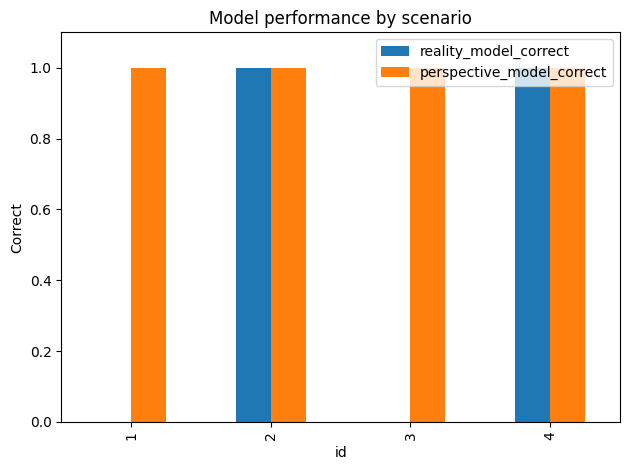

In [3]:
for model in ['reality_model','perspective_model']:
 scenarios[model+'_correct']=(scenarios[model]==scenarios.correct).astype(int)
print(scenarios.groupby('level')[[c for c in scenarios if c.endswith('_correct')]].mean())
scenarios.to_csv('lab16_theory_of_mind.csv',index=False)
scenarios.set_index('id')[[c for c in scenarios if c.endswith('_correct')]].plot(kind='bar',ylim=(0,1.1)); plt.ylabel('Correct'); plt.title('Model performance by scenario'); plt.tight_layout(); plt.show()


## Required investigation
Create four new scenarios that separate reality tracking from belief tracking. Include at least one second-order item. Explain what information each model fails to represent.


In [4]:
# ===== Required investigation: สร้าง 4 scenario ใหม่ (มี second-order อย่างน้อย 1) =====
new_scenarios = pd.DataFrame([
    {'id':101,'level':'first_order','reality':'box','belief':'basket','agent_saw_move':False,'correct':'basket'},
    {'id':102,'level':'first_order','reality':'box','belief':'box','agent_saw_move':True,'correct':'box'},
    {'id':103,'level':'second_order','reality':'fridge','belief':'shelf','agent_saw_move':False,'correct':'shelf'},
    {'id':104,'level':'second_order','reality':'fridge','belief':'fridge','agent_saw_move':True,'correct':'fridge'},
])
new_scenarios['reality_model'] = new_scenarios['reality']
new_scenarios['perspective_model'] = np.where(new_scenarios['agent_saw_move'], new_scenarios['reality'], new_scenarios['belief'])
for m in ['reality_model', 'perspective_model']:
    new_scenarios[m + '_correct'] = (new_scenarios[m] == new_scenarios['correct']).astype(int)
display(new_scenarios)
print(new_scenarios.groupby('level')[['reality_model_correct', 'perspective_model_correct']].mean())
print("reality model ล้มเหลวเมื่อ agent ไม่เห็นการย้าย เพราะมันไม่ได้แทน 'ความเชื่อที่ผิด' ของ agent")


,id,level,reality,belief,agent_saw_move,correct,reality_model,perspective_model,reality_model_correct,perspective_model_correct
0,101,first_order,box,basket,False,basket,box,basket,0,1
1,102,first_order,box,box,True,box,box,box,1,1
2,103,second_order,fridge,shelf,False,shelf,fridge,shelf,0,1
3,104,second_order,fridge,fridge,True,fridge,fridge,fridge,1,1


              reality_model_correct  perspective_model_correct
level                                                         
first_order                     0.5                        1.0
second_order                    0.5                        1.0
reality model ล้มเหลวเมื่อ agent ไม่เห็นการย้าย เพราะมันไม่ได้แทน 'ความเชื่อที่ผิด' ของ agent


## Interpretation and submission

**1. Main numerical result:** perspective model ตอบถูก 100% ทั้งชุดเดิมและชุดใหม่ ส่วน reality model ถูกเฉพาะข้อที่ agent เห็นการย้าย (พลาดข้อ false-belief ทั้งหมด)

**2. Does it support the prediction:** สนับสนุน ตรงตามที่คาด reality model แยกความจริงกับความเชื่อไม่ได้ ส่วน perspective model ติดตามสิ่งที่ agent เห็น/เชื่อได้

**3. Alternative explanation & design improvement:** ทางเลือก: การที่ perspective model ถูกหมด ไม่ได้แปลว่ามันมี ToM จริง มันแค่ทำตามกฎที่เราเขียน / ปรับปรุง: เพิ่ม scenario ที่ซับซ้อนขึ้น (เช่น สอง agent เห็นคนละส่วน) และทดสอบว่ากฎยัง generalize ไหม

**4. Files:** ดาวน์โหลด notebook นี้พร้อมไฟล์ CSV ที่ถูกสร้างขึ้นทุกไฟล์เพื่อส่ง

> ข้อควรระวัง: การผ่าน false-belief task ไม่ได้พิสูจน์ว่าระบบมีจิตหรือ consciousness

## AI use declaration

- Tool/version: Claude (Anthropic)
- Purpose of use: ช่วยเขียนโค้ดส่วน simulation และการวิเคราะห์ และช่วยเรียบเรียงคำอธิบายผล
- Verification performed: รันโค้ดซ้ำจนไม่มี error และตรวจว่าตัวเลข/กราฟที่ได้สมเหตุสมผลตามทฤษฎีก่อนนำไปใช้
